# 06 · Mosaicismo: señal BAF y prototipo MitoRead

> **Lugar en el argumento:** extensión metodológica. Explica un modo de fallo de la señal BAF
> cuando la aneuploidía es variegada y separa esa simulación de un piloto técnico de MitoRead.
>
> **Salida principal:** simulación preregistrada + prueba de factibilidad técnica. Ninguna de
> las dos es una medición funcional del paciente.

> **Este notebook tiene dos partes y NO se mezclan.**
>
> | Parte | Qué es |
> |---|---|
> | **A · simulación** | `SIMULATED`. **Ningún dato del paciente.** Cómputo puro |
> | **B · MitoRead** | `DERIVED`. Un **prototipo técnico**, no una medida del paciente |
>
> Confundirlas sería exactamente el error que el brief prohíbe: presentar una medida derivada
> de cobertura como si fuera un ensayo funcional.

### Integración visual · 24 septiembre 2026

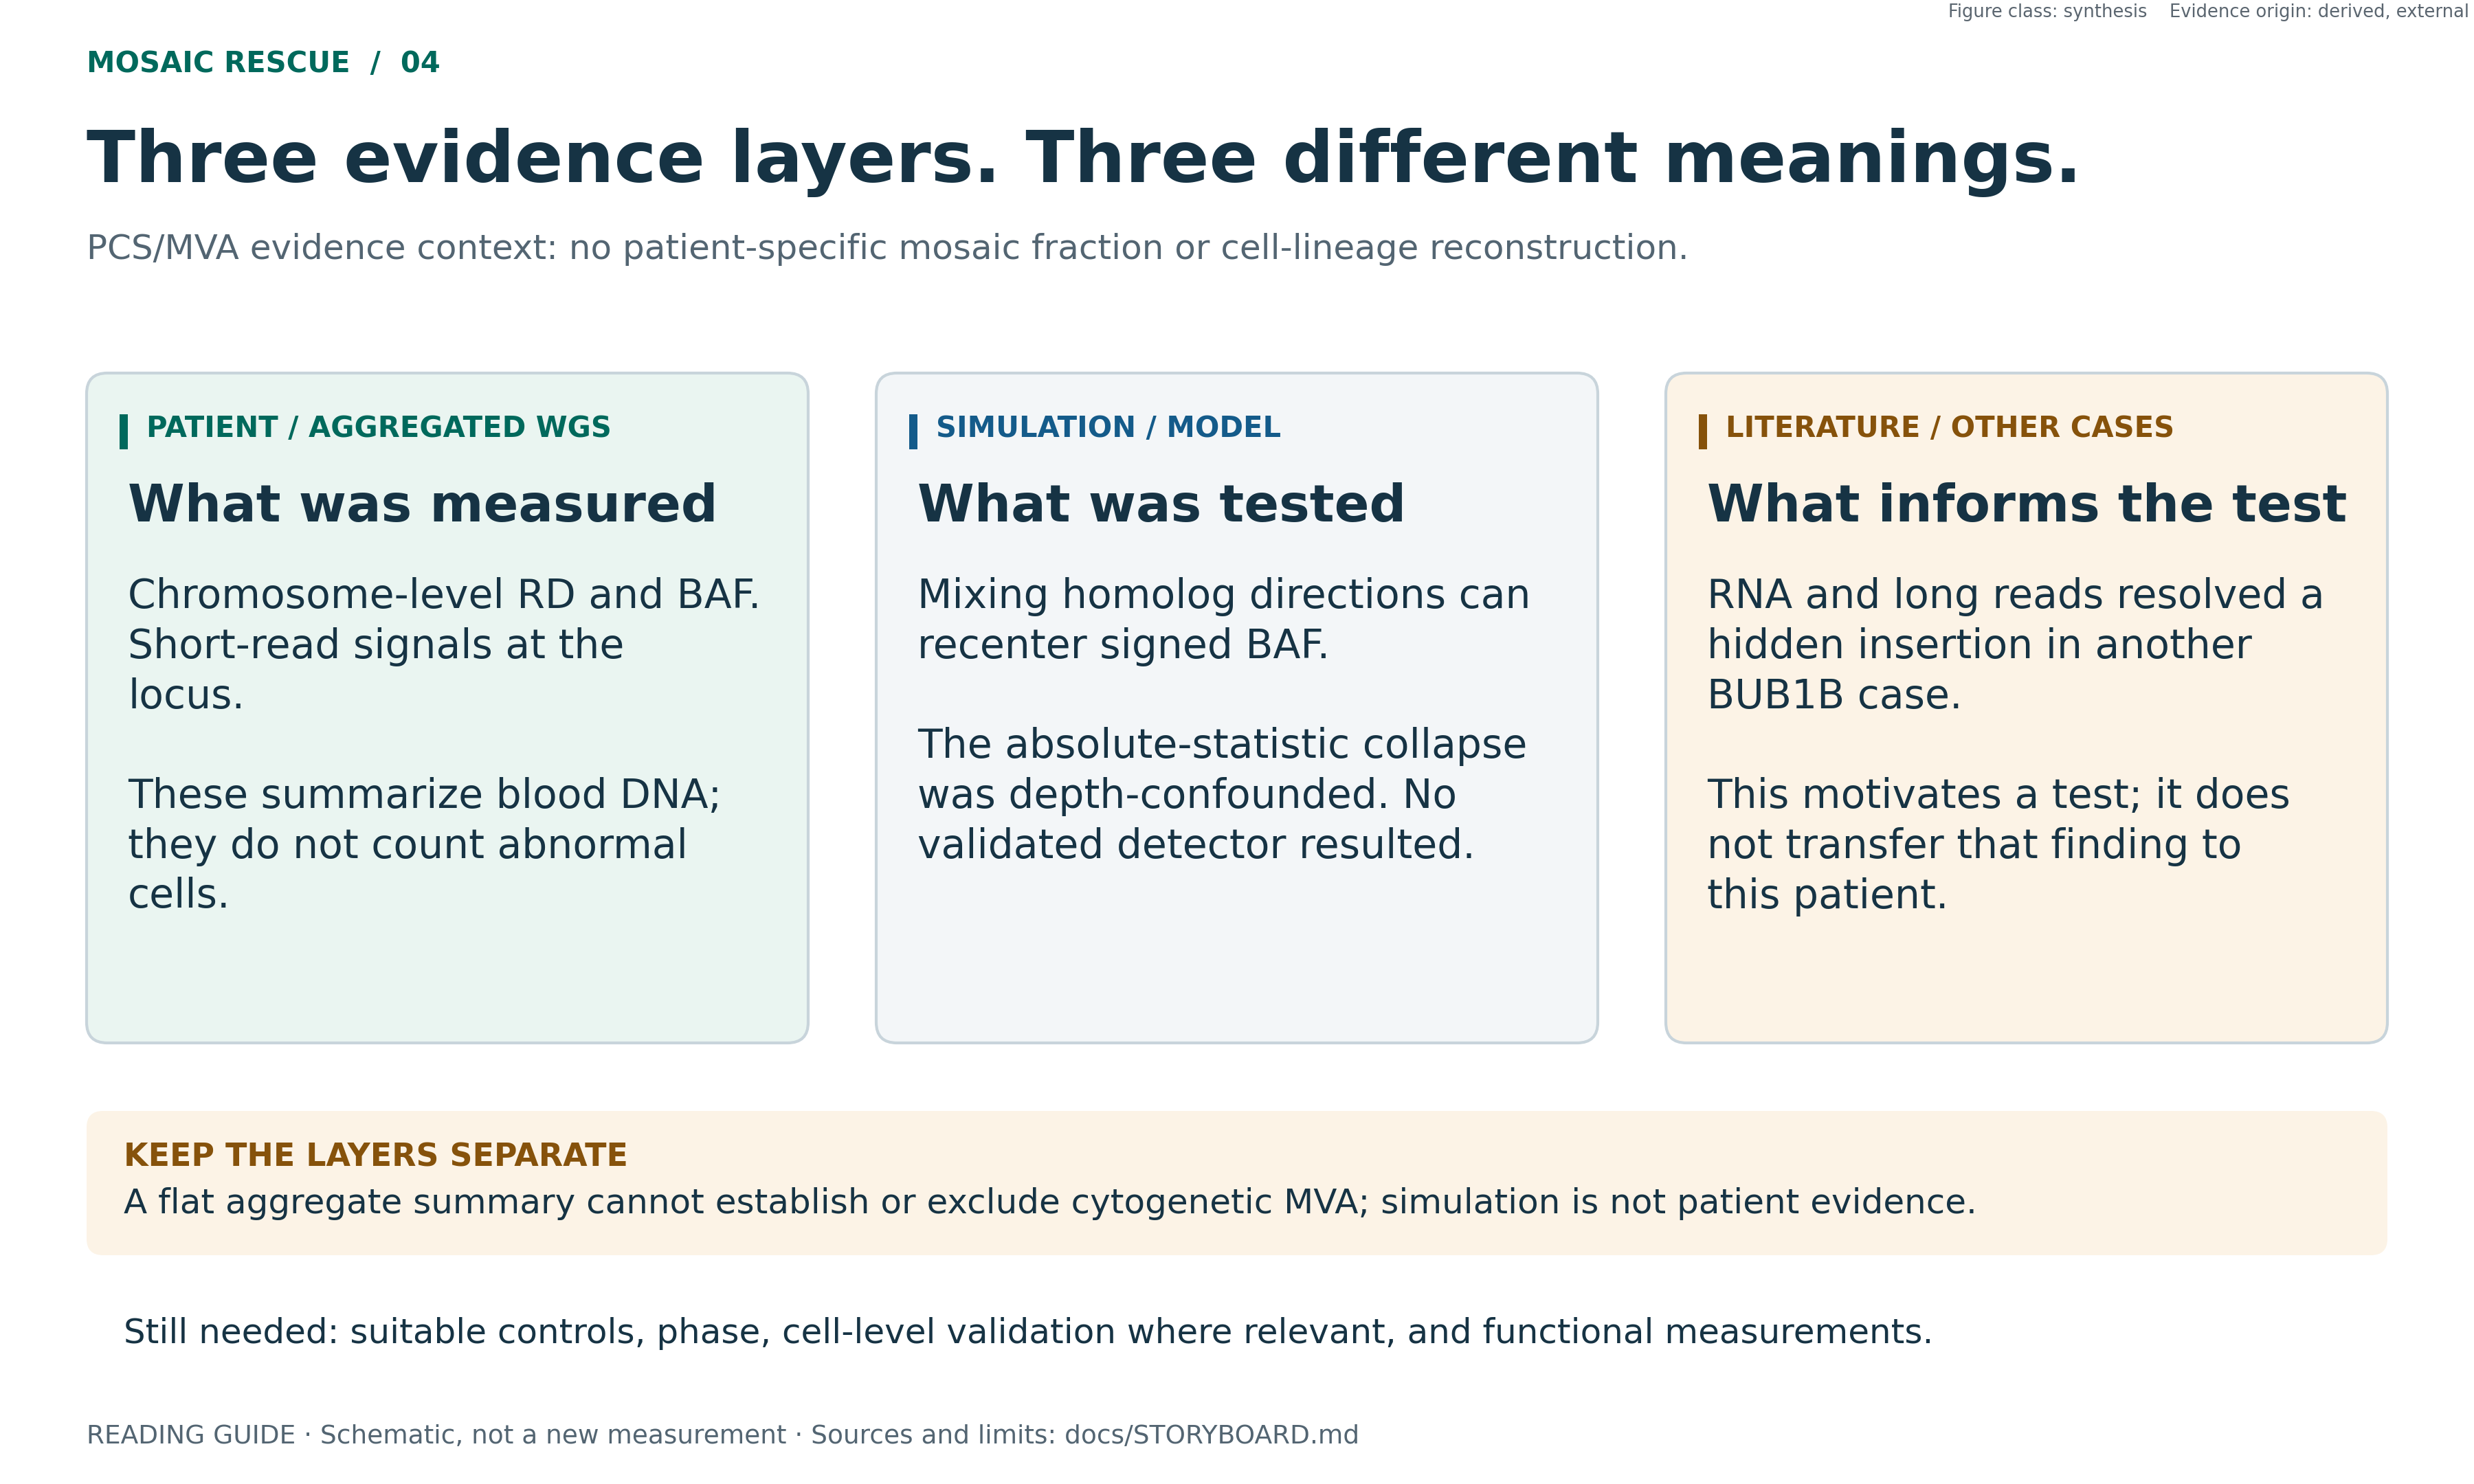

**SYNTHESIS · DERIVED / EXTERNAL.** WGS del caso, simulación y literatura responden preguntas diferentes.

Figura importada del artefacto revisado, sin reejecutar el análisis original. [Fuentes y límites](../docs/STORYBOARD.md) · [QA](../PUBLICATION_FIGURE_QA.md).

### Integración visual · 24 septiembre 2026

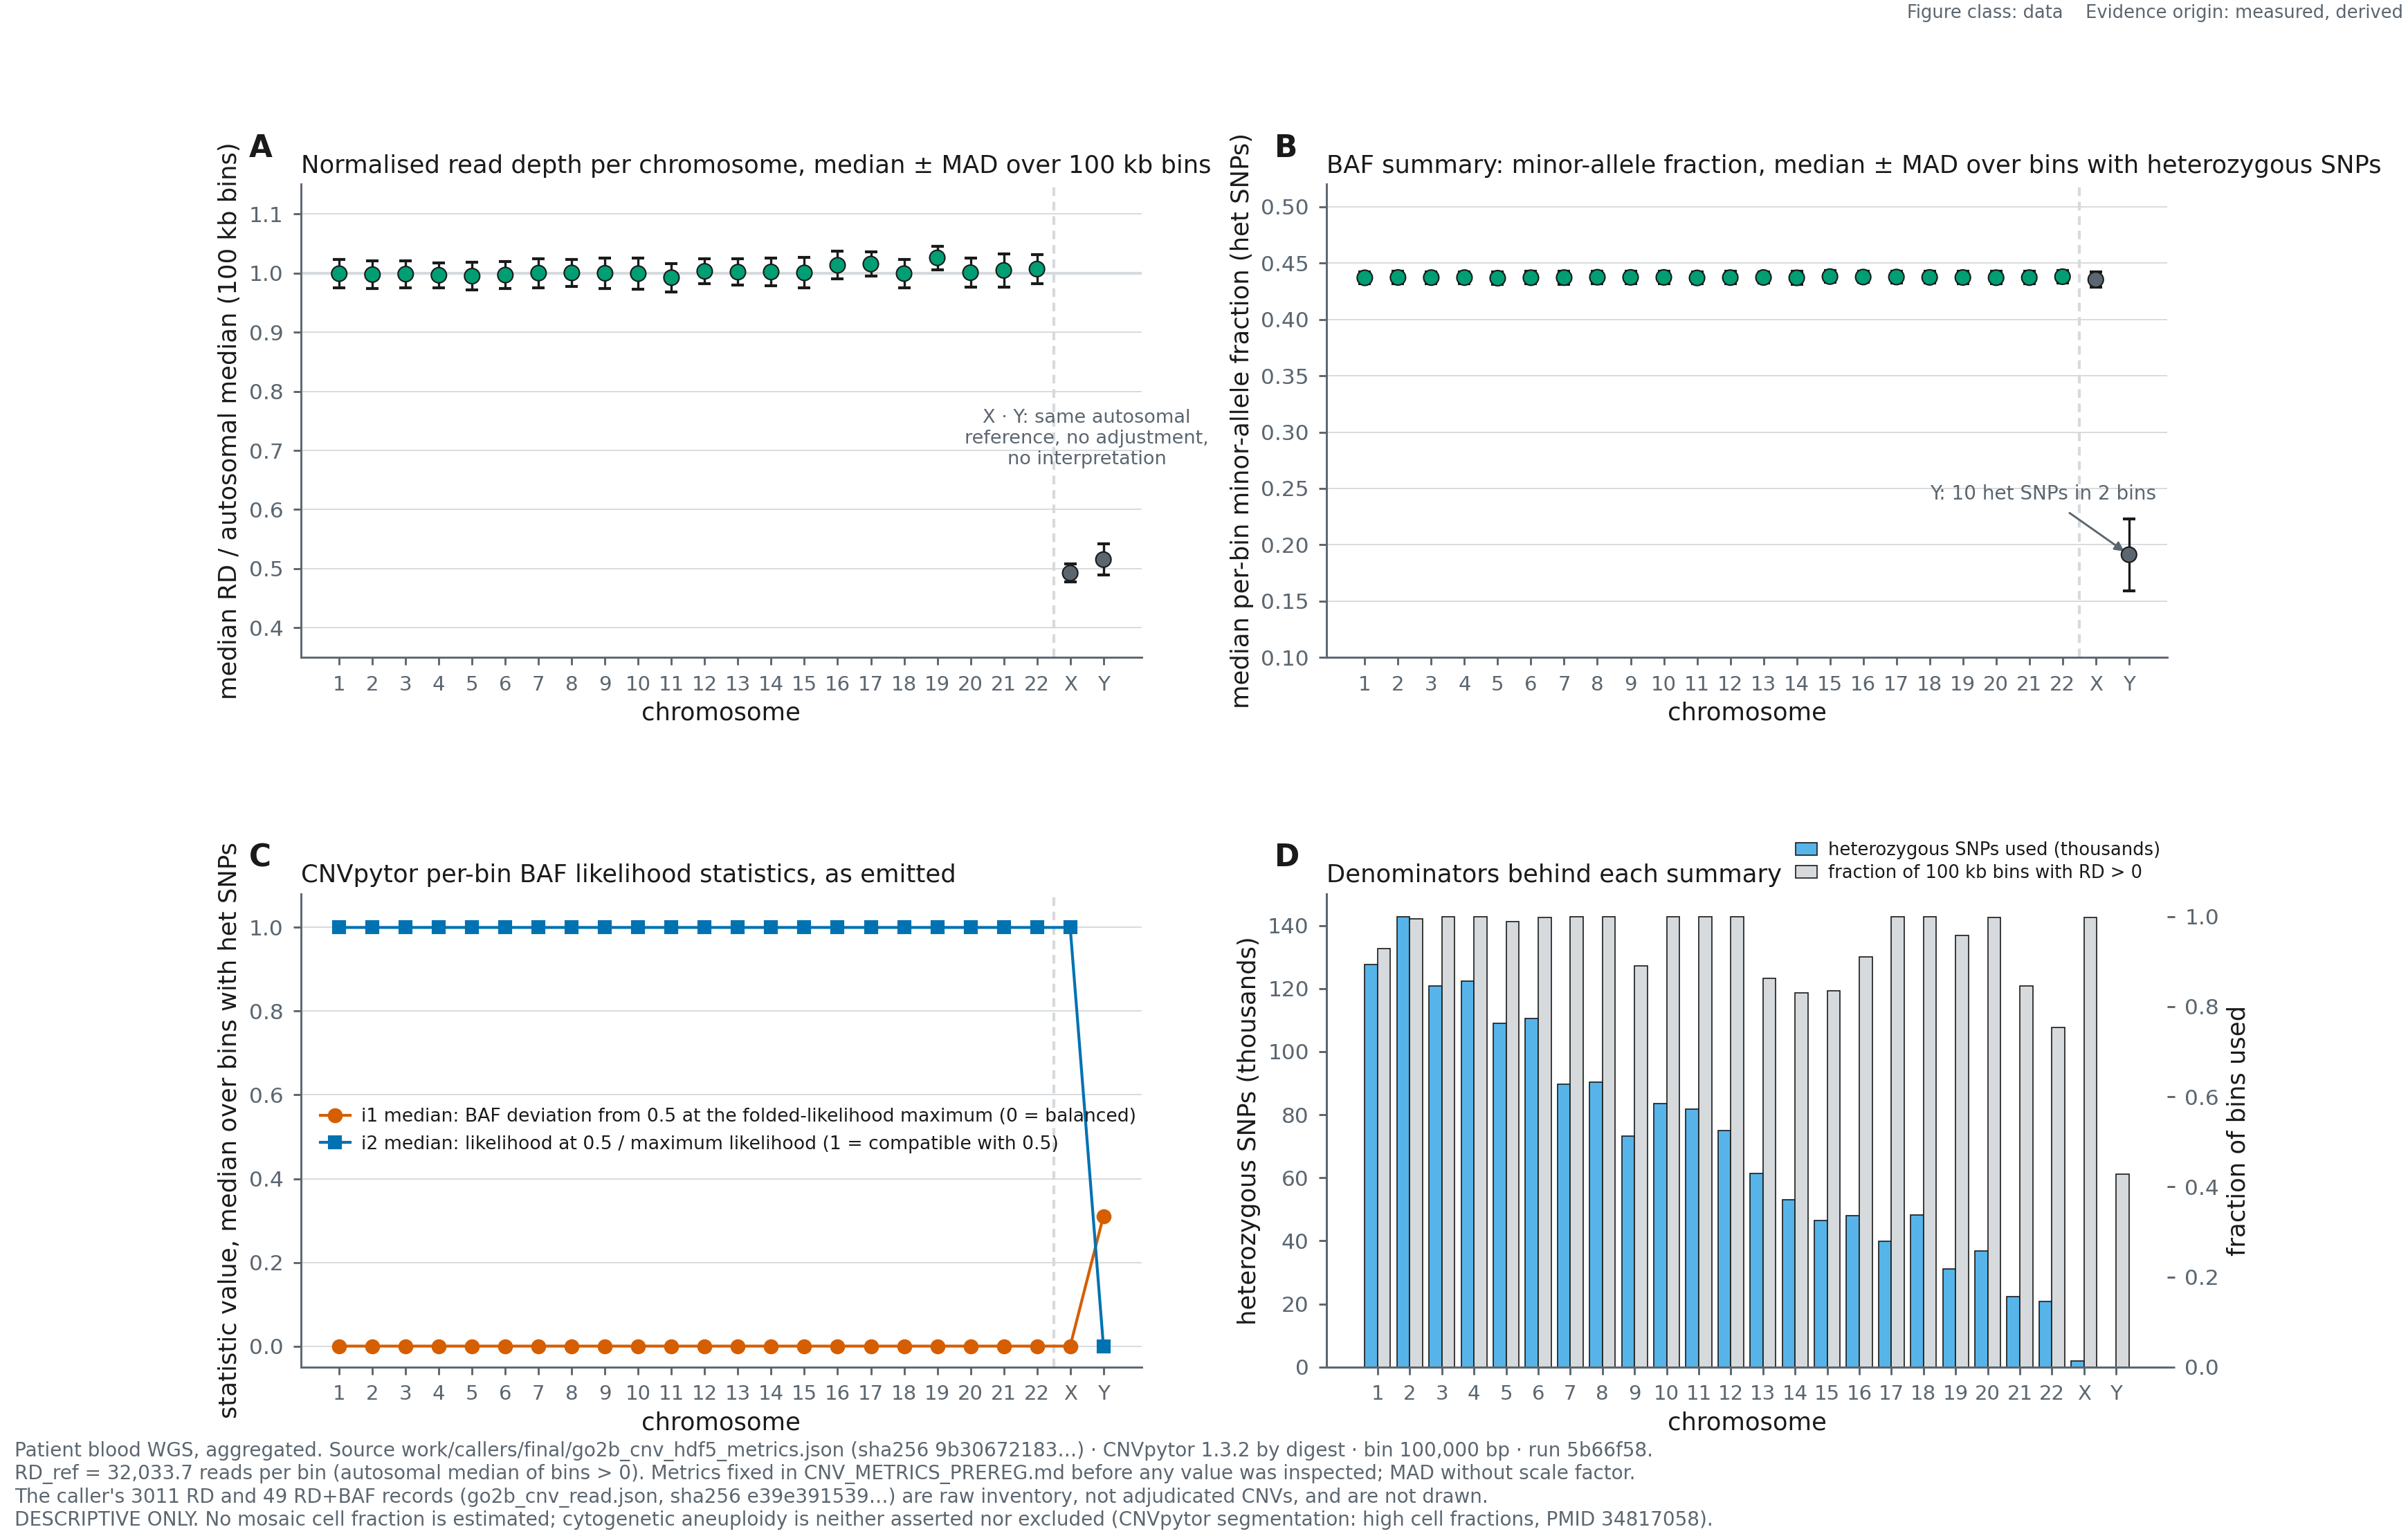

**DATA · MEASURED / DERIVED.** GO 2B, resultado agregado ya congelado: RD/BAF descriptivos por cromosoma. No es cariotipo ni estima fracción mosaico. Fuente y hash en el pie original y ficha QA.

Figura importada del artefacto revisado, sin reejecutar el análisis original. [Fuentes y límites](../docs/STORYBOARD.md) · [QA](../PUBLICATION_FIGURE_QA.md).

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


In [2]:
fl.labels("Que muestra la simulacion", "Lo que no transfiere al caso")

# Parte A · La cancelación de BAF

## Pregunta biológica

MVA es **variegada**: cada linaje gana o pierde cromosomas de forma independiente. Los métodos
estándar de mosaicismo asumen **clonalidad**, una célula ancestral, un solo homólogo.

**¿Qué le pasa a la señal cuando ese supuesto se rompe?**

## Hipótesis y preregistro

`docs/DECISIONS.md` § EXP-015a, escrito **antes** de implementar. Cuatro predicciones con su
regla de decisión. La #3 era la que decidía: si el índice de dispersión no conserva potencia
donde el BAF se cancela, **no aporta nada y se abandona**.

El álgebra que se pone a prueba:

```
CLONAL      todas las celulas ganan el MISMO homologo
            BAF = 1/(2+f) ~ 0,5 - f/4        senal
VARIEGADO   cada linaje gana uno al azar
            BAF = 0,5 EXACTO                 cancelacion completa
            cobertura = 2 + f                SOBREVIVE
```

In [3]:
sim = json.load(io.open("work/mosaic/dispersion_simulation.json", encoding="utf-8"))
print(f"  semilla {sim['seed']} · {sim['n_rep']} repeticiones · profundidad {sim['depth']}x"
      f" · FPR fijada {sim['alpha']}")
print()
print(f"  {'escenario':<14}{'fraccion':>10}{'potencia BAF':>15}{'potencia DISPERSION':>22}")
for r in sim["results"]:
    print(f"  {r['mode']:<14}{r['fraction']*100:>9.0f}%{r['power_baf']:>15.3f}"
          f"{r['power_dispersion']:>22.3f}")

  semilla 42 · 200 repeticiones · profundidad 44x · FPR fijada 0.05

  escenario       fraccion   potencia BAF   potencia DISPERSION
  clonal                1%          0.045                 0.060
  clonal                2%          0.035                 0.100
  clonal                5%          0.070                 0.380
  clonal               10%          0.280                 0.975
  clonal               20%          1.000                 1.000
  variegated            1%          0.055                 0.060
  variegated            2%          0.030                 0.095
  variegated            5%          0.030                 0.300
  variegated           10%          0.015                 0.960
  variegated           20%          0.000                 1.000


### Figura principal A · las distribuciones de BAF, no el resumen

Un promedio no puede enseñar una cancelación: el estadístico resumido de un genoma variegado se
parece al de un genoma euploide, y esa es exactamente la trampa. Lo que hay que mirar es **la
distribución de BAF sitio a sitio**, con la misma escala en los tres escenarios.

In [4]:
from src.mosaic.simulate_dispersion import site_bafs, SEED, FRACTIONS, DEPTH, N_SITES
from src.figures import fig06_baf as FBAF

F = 0.20                                   # la fraccion donde la cancelacion es total
SCEN = [("A · euploide", "null", 0.0, fl.SOFT),
        ("B · clonal (mismo homologo en todas las celulas)", "clonal", F, fl.FLOW),
        ("C · variegado (homologo al azar por linaje)", "variegated", F, fl.VOID)]
BAFS = {k: site_bafs(SEED + i, f, m) for i, (k, m, f, _c) in enumerate(SCEN)}
# Mismas trazas, con las etiquetas en ingles que usa la figura de publicacion.
BAFS_PUB = {lab: site_bafs(SEED + i, 0.0 if mode == "null" else F, mode)
            for i, (lab, mode, _col) in enumerate(FBAF.SCEN)}

print(f"  semilla {SEED} · profundidad {DEPTH}x · {N_SITES} sitios por cromosoma · "
      f"3 cromosomas afectados · fraccion celular {F*100:.0f} %")
print()
print(f"  {'escenario':<48}{'n sitios':>10}{'|BAF-0,5| medio':>18}{'BAF medio':>12}")
for k, m, f, _c in SCEN:
    v = np.asarray(BAFS[k])
    print(f"  {k:<48}{len(v):>10}{np.abs(v - 0.5).mean():>18.4f}{v.mean():>12.4f}")

  semilla 42 · profundidad 44x · 400 sitios por cromosoma · 3 cromosomas afectados · fraccion celular 20 %

  escenario                                         n sitios   |BAF-0,5| medio   BAF medio
  A · euploide                                          1200            0.0611      0.5041
  B · clonal (mismo homologo en todas las celulas)      1200            0.0677      0.5456
  C · variegado (homologo al azar por linaje)           1200            0.0605      0.4997


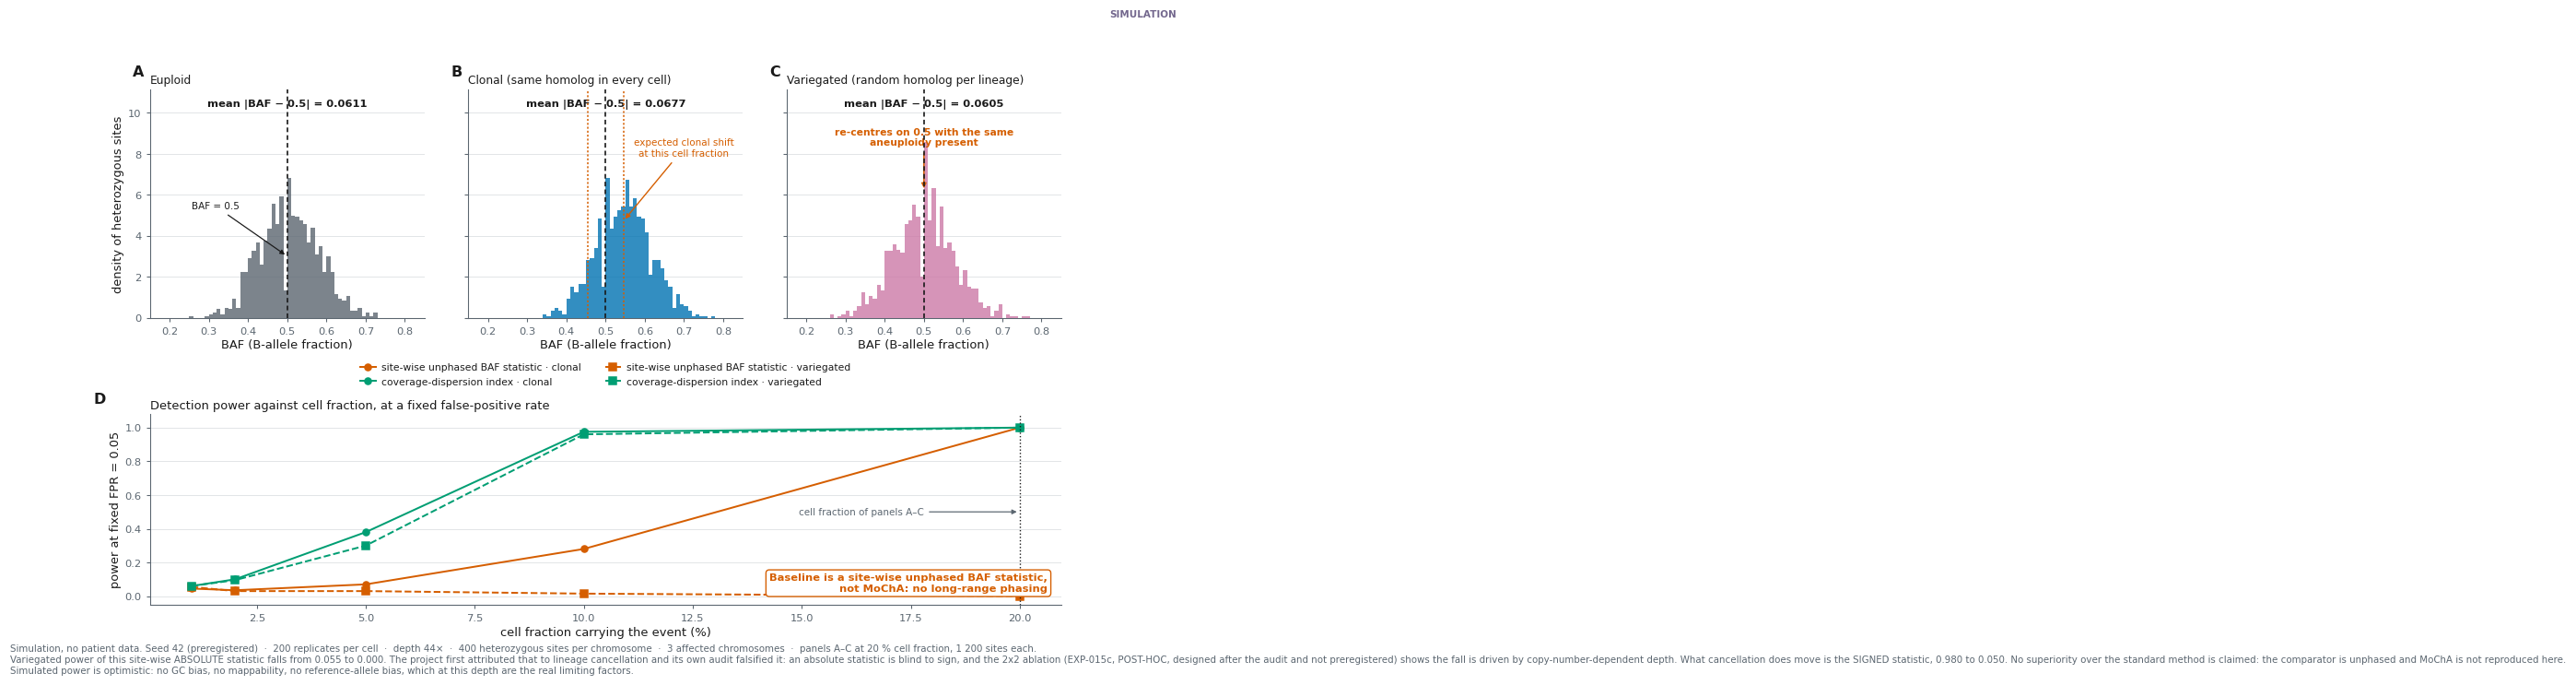

> **Figura principal A · distribuciones de BAF y potencia**  
> `EXP-015a` · figure class `SIMULATION`, figura cientifica · evidence origin `SIMULATED`  
> *Que muestra la simulacion.* el recentrado, visto donde ocurre y con la MISMA escala en los tres paneles: el euploide se centra en 0,5; el clonal se desplaza hacia los dos modos esperados, marcados; y el variegado, con la misma fraccion celular de aneuploidia, VUELVE a centrarse en 0,5. El panel D cuantifica el estadistico ABSOLUTO, cuya potencia en variegado cae de 0.055 a 0.000. ATENCION: esa caida NO la produce la cancelacion. Una ablacion POST-HOC, EXP-015c, disenada DESPUES de la auditoria y por tanto NO preregistrada, lo falso -- un valor absoluto es ciego al signo -- y la produce la profundidad dependiente del numero de copia. Lo que la cancelacion SI mueve es el estadistico CON SIGNO, de 0,980 a 0,050.  
> **Lo que no transfiere al caso.** nada sobre el paciente: no hay ni un dato suyo. Y no demuestra superioridad sobre el metodo estandar: el comparador es una desviacion de BAF por sitio y sin fase, que no es MoChA, y eso esta escrito dentro del panel para que sobreviva a un recorte. La potencia simulada es ademas optimista: sin sesgo de GC, sin mapabilidad y sin sesgo de alelo de referencia.  
> datos: `src/mosaic/simulate_dispersion.py · semilla 42` · libreria: `matplotlib` · procedencia: `figures/pub/fig06_baf_cancellation.svg + .png 300 dpi`

In [5]:
from src.figures import fig06_baf as FBAF

fig = FBAF.build(sim, BAFS_PUB, F)
_pv = [r["power_baf"] for r in sim["results"] if r["mode"] == "variegated"]
fl.pub(fig, "Figura principal A · distribuciones de BAF y potencia",
       "EXP-015a", "SIMULATED", "SIMULATION",
       f"el recentrado, visto donde ocurre y con la MISMA escala en los tres paneles: el "
       f"euploide se centra en 0,5; el clonal se desplaza hacia los dos modos esperados, "
       f"marcados; y el variegado, con la misma fraccion celular de aneuploidia, VUELVE a "
       f"centrarse en 0,5. El panel D cuantifica el estadistico ABSOLUTO, cuya potencia en "
       f"variegado cae de {_pv[0]:.3f} a {_pv[-1]:.3f}. ATENCION: esa caida NO la produce la "
       f"cancelacion. Una ablacion POST-HOC, EXP-015c, disenada DESPUES de la auditoria y por "
       f"tanto NO preregistrada, lo falso -- un valor absoluto es ciego al signo -- y la produce "
       f"la profundidad dependiente del numero de copia. Lo que la cancelacion SI mueve es el "
       f"estadistico CON SIGNO, de 0,980 a 0,050.",
       "nada sobre el paciente: no hay ni un dato suyo. Y no demuestra superioridad sobre el "
       "metodo estandar: el comparador es una desviacion de BAF por sitio y sin fase, que no es "
       "MoChA, y eso esta escrito dentro del panel para que sobreviva a un recorte. La "
       "potencia simulada es ademas optimista: sin sesgo de GC, sin mapabilidad y sin sesgo "
       "de alelo de referencia.",
       source=f"src/mosaic/simulate_dispersion.py · semilla {sim['seed']}",
       lib="matplotlib", slug="fig06_baf_cancellation")

### La misma conclusión, en la figura publicada del proyecto

### Robustez · las cuatro predicciones, con el marcador

Dos se confirmaron y **dos fallaron**. La #4 falló de una forma que obliga a rebajar la
conclusión, y por eso las dos hipótesis se separan.

> **Y la #2 hubo que partirla en dos.** Se marcó como confirmada leyéndola sobre el estadístico
> **absoluto**, y ahí la caída no la produce la cancelación sino la profundidad (EXP-015c, una
> ablación diagnóstica **post-hoc**, no preregistrada). Sobre
> el estadístico **con signo**, que es al que la cancelación puede afectar, la predicción se
> cumple: 0,980 → 0,050. El marcador de abajo conserva la lectura original; la corrección va
> aquí, al lado, porque el preregistro no se reescribe.

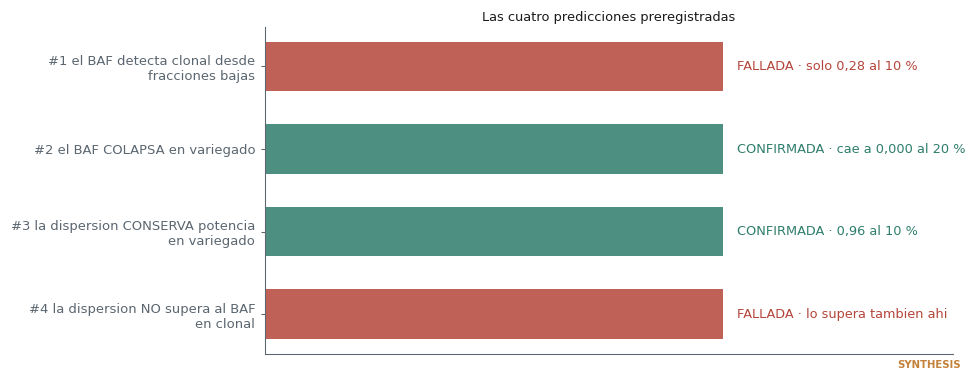

> **Figura de robustez A · marcador de las predicciones**  
> `EXP-015a` · figure class `SYNTHESIS`, no es un dato: synthesis · evidence origin `SIMULATED`  
> *Que muestra la simulacion.* la #2 y la #3 confirman el mecanismo BAJO LA SIMULACION PREREGISTRADA: la cancelacion se reproduce en el comparador SITIO-A-SITIO y SIN FASE que se usa aqui, que NO es MoChA, y esto no demuestra superioridad frente a un metodo CON fase. La dispersion sobrevive a el. La #4 fallo, y eso REVELA que la linea base de BAF usada es debil, no que nuestro estadistico sea superior.  
> **Lo que no transfiere al caso.** nada sobre el paciente. Y la potencia simulada es OPTIMISTA: el modelo no incluye sesgo de GC, mapabilidad ni sesgo de alelo de referencia, que a 44x son el factor limitante real. Por debajo del 5 % de fraccion celular no hay potencia en ninguno de los dos metodos.  
> procedencia: `work/mosaic/dispersion_simulation.json · semilla 42`

In [6]:
PRED = [
 ("#1 el BAF detecta clonal desde\nfracciones bajas",      0, "solo 0,28 al 10 %"),
 ("#2 el BAF COLAPSA en variegado",                        1, "cae a 0,000 al 20 %"),
 ("#3 la dispersion CONSERVA potencia\nen variegado",      1, "0,96 al 10 %"),
 ("#4 la dispersion NO supera al BAF\nen clonal",          0, "lo supera tambien ahi"),
]
fig, ax = plt.subplots(figsize=(8.8, 3.4))
labs = [p[0] for p in PRED][::-1]
ok = [p[1] for p in PRED][::-1]
note = [p[2] for p in PRED][::-1]
ax.barh(range(len(labs)), [1]*len(labs), color=[fl.ALIVE if o else fl.DEAD for o in ok],
        alpha=0.85, height=0.6)
ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs, fontsize=8.6)
ax.set_xticks([]); ax.set_xlim(0, 1.5); ax.grid(False)
for i, (o, n) in enumerate(zip(ok, note)):
    ax.text(1.03, i, ("CONFIRMADA · " if o else "FALLADA · ") + n, va="center",
            fontsize=8.4, color=fl.ALIVE if o else fl.DEAD)
ax.set_title("Las cuatro predicciones preregistradas")

fl.done(fig, "Figura de robustez A · marcador de las predicciones", "EXP-015a", "SIMULATED",
        "SYNTHESIS",
        "la #2 y la #3 confirman el mecanismo BAJO LA SIMULACION PREREGISTRADA: la cancelacion se reproduce en el comparador SITIO-A-SITIO y SIN FASE que se usa aqui, que NO es MoChA, y esto no demuestra superioridad frente a un metodo CON fase. La "
        "dispersion sobrevive a el. La #4 fallo, y eso REVELA que la linea base de BAF usada "
        "es debil, no que nuestro estadistico sea superior.",
        "nada sobre el paciente. Y la potencia simulada es OPTIMISTA: el modelo no incluye "
        "sesgo de GC, mapabilidad ni sesgo de alelo de referencia, que a 44x son el factor "
        "limitante real. Por debajo del 5 % de fraccion celular no hay potencia en ninguno "
        "de los dos metodos.",
        prov="work/mosaic/dispersion_simulation.json · semilla 42")

### Decisión de la parte A

| Hipótesis | Estado |
|---|---|
| **EXP-015a · el mecanismo de cancelación** | **SURVIVES**, modo de fallo reproducido y cuantificado |
| **EXP-015b · el índice como DETECTOR** | **PARKED · no validado**, el comparador no es MoChA |

**Prohibido decir** «enormemente más potente» o «supera a MoChA». Lo que subió de estatus es el
**mecanismo**, no el rendimiento relativo.

**La rama aplicada sigue BLOCKED:** exige controles procesados con pipeline idéntico, y no
existen.

---

# Parte B · MitoRead

## Corrección de una clasificación propia errónea

Esta rama se declaró bloqueada porque «el VCF no contiene variantes mitocondriales». **Eso es
irrelevante**: `mtDNA-CN` es un **cociente de cobertura** y no necesita ninguna variante. La
rama estaba mal clasificada.

| | |
|---|---|
| **EXP-014a · piloto técnico** | ejecutable con L001 |
| **EXP-014b · interpretación biológica** | **BLOCKED** |

In [7]:
mp = json.load(io.open("work/mito/pilot_l001.json", encoding="utf-8"))
print(f"  lecturas examinadas          : {mp['reads']:,}")
print(f"  compatibles con mitocondrial : {mp['mito_reads']:,}  ({100*mp['fraction']:.4f} %)")
print(f"  estimacion ingenua           : {mp['mtdna_cn_estimate']:.0f} copias-equivalentes")
print()
print(f"  interpretable: {mp['interpretable']}")
print(f"  por que no   : {mp['why_not']}")

  lecturas examinadas          : 2,000,000
  compatibles con mitocondrial : 1,382  (0.0691 %)
  estimacion ingenua           : 259 copias-equivalentes

  interpretable: False
  por que no   : NUMT no excluidos; un solo carril; sin controles; sin hemograma


### Figura · el número, y por qué no es un resultado

**No** se dibuja una barra que diga «paciente = 259». Se dibuja **la estimación junto a las
fuentes de incertidumbre que no están cuantificadas**, para que sea imposible confundirla con
una medida.

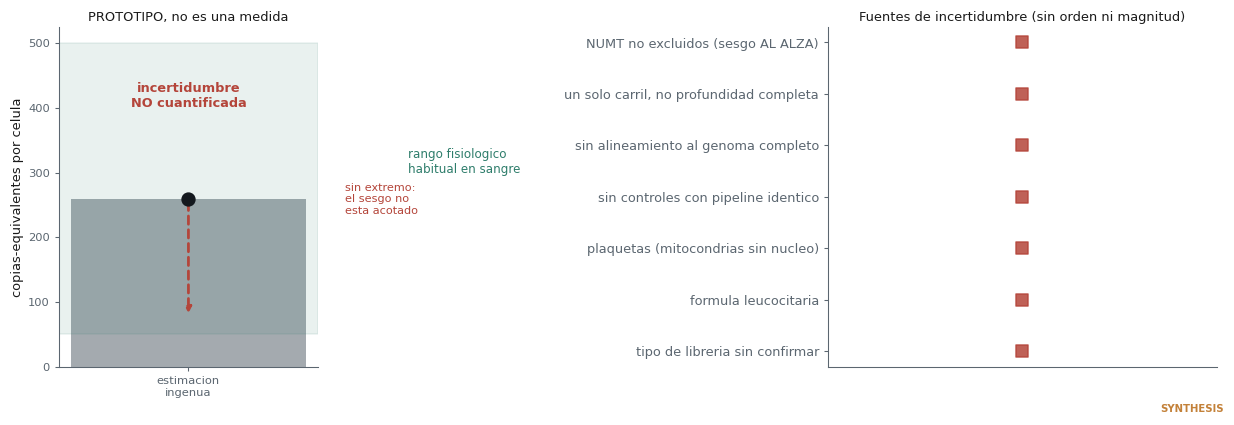

> **Figura B · el prototipo y su incertidumbre, juntos**  
> `EXP-014a` · figure class `SYNTHESIS`, no es un dato: synthesis · evidence origin `DERIVED`  
> *Que muestra la simulacion.* la senal es extraible: 0.069 % de las lecturas de L001 son compatibles con el genoma mitocondrial, y el cociente da ~259 copias-equivalentes. **Eso valida que la rama es tecnicamente ejecutable.**  
> **Lo que no transfiere al caso.** NADA sobre la biologia del paciente. Que el valor caiga en el rango fisiologico es precisamente lo que lo hace peligroso, no lo que lo respalda. La formulacion correcta es *naive mtDNA-equivalent estimate bajo los supuestos del piloto*, NUNCA 'mtDNA-CN del paciente'. Y no hay barras de error a proposito: la incertidumbre esta declarada NO CUANTIFICADA, asi que un intervalo dibujado seria un numero inventado. Las flechas SIN extremo dicen lo unico cierto: el sesgo no esta acotado.  
> procedencia: `submuestra de L001 R1 · k-meros de 31 pb contra la referencia mitocondrial`

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.8),
                         gridspec_kw={"width_ratios": [1, 1.5]})

est = mp["mtdna_cn_estimate"]
# SIN barras de error. La incertidumbre esta declarada NO CUANTIFICADA: dibujar
# un intervalo equivale a inventarse el numero que falta. Se dibuja el punto y,
# encima, una banda ABIERTA sin extremo, que es lo que de verdad sabemos.
axes[0].bar(["estimacion\ningenua"], [est], color=fl.SOFT, alpha=0.55, width=0.45)
axes[0].scatter([0], [est], s=70, color=fl.INK, zorder=5)
axes[0].annotate("", xy=(0, est * 2.05), xytext=(0, est),
                 arrowprops=dict(arrowstyle="-|>", color=fl.DEAD, lw=1.8, ls=(0, (3, 2))))
axes[0].annotate("", xy=(0, est * 0.30), xytext=(0, est),
                 arrowprops=dict(arrowstyle="-|>", color=fl.DEAD, lw=1.8, ls=(0, (3, 2))))
axes[0].text(0.30, est, "sin extremo:" + chr(10) + "el sesgo no" + chr(10) + "esta acotado",
             fontsize=7.4, color=fl.DEAD, va="center")
axes[0].axhspan(50, 500, color=fl.ALIVE, alpha=0.10)
axes[0].text(0.42, 300, "rango fisiologico\nhabitual en sangre", fontsize=7.8, color=fl.ALIVE)
axes[0].set_ylabel("copias-equivalentes por celula")
axes[0].set_title("PROTOTIPO, no es una medida")
axes[0].text(0, est * 1.55, "incertidumbre\nNO cuantificada", ha="center", fontsize=8.4,
             color=fl.DEAD, fontweight="bold")

SRC = ["NUMT no excluidos (sesgo AL ALZA)",
       "un solo carril, no profundidad completa",
       "sin alineamiento al genoma completo",
       "sin controles con pipeline identico",
       "plaquetas (mitocondrias sin nucleo)",
       "formula leucocitaria",
       "tipo de libreria sin confirmar"]
# Ninguna longitud: estas fuentes no estan cuantificadas ni ordenadas. Las barras
# antiguas tenian valores decorativos y sugerian una jerarquia inexistente.
axes[1].scatter(np.zeros(len(SRC)), range(len(SRC)), marker="s", s=68,
                color=fl.DEAD, alpha=0.85)
axes[1].set_yticks(range(len(SRC)))
axes[1].set_yticklabels(SRC, fontsize=8.4)
axes[1].invert_yaxis()
axes[1].set_xticks([]); axes[1].set_xlim(-0.08, 0.08); axes[1].grid(False)
axes[1].set_title("Fuentes de incertidumbre (sin orden ni magnitud)")

fl.done(fig, "Figura B · el prototipo y su incertidumbre, juntos", "EXP-014a", "DERIVED",
        "SYNTHESIS",
        f"la senal es extraible: {100*mp['fraction']:.3f} % de las lecturas de L001 son "
        f"compatibles con el genoma mitocondrial, y el cociente da ~{est:.0f} "
        "copias-equivalentes. **Eso valida que la rama es tecnicamente ejecutable.**",
        "NADA sobre la biologia del paciente. Que el valor caiga en el rango fisiologico es "
        "precisamente lo que lo hace peligroso, no lo que lo respalda. La formulacion correcta "
        "es *naive mtDNA-equivalent estimate bajo los supuestos del piloto*, NUNCA "
        "'mtDNA-CN del paciente'. Y no hay barras de error a proposito: la incertidumbre esta "
        "declarada NO CUANTIFICADA, asi que un intervalo dibujado seria un numero inventado. "
        "Las flechas SIN extremo dicen lo unico cierto: el sesgo no esta acotado.",
        prov="submuestra de L001 R1 · k-meros de 31 pb contra la referencia mitocondrial")

### Decisión de la parte B

| | |
|---|---|
| **EXP-014a** | **UNRESOLVED · prototipo**, la señal es extraíble; nada está calibrado |
| **EXP-014b** | `BLOCKED`, a la espera de BAM/CRAM completo, controles y hemograma |
| **EXP-014a-v2** (alineamiento para excluir NUMT) | **PARKED**, sin alineador instalable y descargar binarios está prohibido por política |

### El supuesto más atacable de toda la rama

Que la `mtDNA-CN` en **sangre periférica** refleje el estado mitocondrial de músculo y riñón.
Y con n=1 bulk **no hay gradiente interno**: es un punto, no una curva dosis-respuesta.

### Siguiente experimento

Alineamiento al genoma completo con exclusión de NUMT, **controles** procesados con pipeline
idéntico, y el **hemograma contemporáneo**, que sigue sin respuesta y es un email.